# Search TPS pathway members for prior disease and literature reports - December 9, 2016
Use UniProt cross-references to OMIM and PubMed to assess how much is "known" about each protein.  This notebook builds distributions for OMIM and PubMed associations for all human proteins.  These are constructed first for only the reviewed, SwissProt protein identifiers and then for all human protein identifiers.  Given those distributions, it finds TPS pathway members that are very well-studied (per OMIM and PubMed) or not well-studied.

The distribution for reviewed proteins nominates 5 very well-studied and 5 less-studied TPS members that could be good candidates for validation.

## Initialize

In [1]:
%pylab inline
import pandas as pd
import numpy as np
import os

# All human proteins, on 12/9/16 query 'organism:"Homo sapiens (Human) [9606]"'
all_annot_file = os.path.join('..','..','UniProt','uniprot-all-omim-pmid-120916.txt.gz')
# Reviewed human proteins: on 12/9/16 query 'reviewed:yes AND organism:"Homo sapiens (Human) [9606]"'
reviewed_annot_file = os.path.join('..','..','UniProt','uniprot-reviewed-omim-pmid-120916.txt.gz')

tps_network_file = os.path.join('..','..','synthesis072614','p-0.01_202dir.xlsx')

Populating the interactive namespace from numpy and matplotlib


## Helper functions to load the UniProt annotations, compile the OMIM and PubMed distributions, and plot histograms
OMIM uses the column **Involvement in disease**.  PubMed is based on the columns **PubMed ID**, which is presumably manually-curated, and **Mapped PubMed ID**, which is computationally mapped.

In [2]:
def pmid_count(pmid_list):
    pmid_list = str(pmid_list)
    if pmid_list.lower() == 'nan':
        return 0
    else:
        return len(pmid_list.split(';'))

def load_annotations(uniprot_file):
    annot_df = pd.read_csv(uniprot_file, sep='\t')
    print 'Loaded {} UniProt annotations'.format(len(annot_df))
    
    # Transform the OMIM and PubMed columns into counts
    assert 'Involvement in disease' in annot_df.columns
    assert 'PubMed ID' in annot_df.columns
    assert 'Mapped PubMed ID' in annot_df.columns
    
    # OMIM entries contain ids of the form [MIM:275355]
    # If nan, will be converted to the string 'nan' and correctly return 0
    annot_df['OMIM count'] = annot_df.apply(lambda row: str(row['Involvement in disease']).count('[MIM:'), axis=1)
    # PMIDs are ; delimited
    annot_df['PubMed ID count'] = annot_df.apply(lambda row: pmid_count(row['PubMed ID']), axis=1)
    annot_df['Mapped PubMed ID count'] = annot_df.apply(lambda row: pmid_count(row['Mapped PubMed ID']), axis=1)

    # Verify parsing with known counts
    if 'P53_HUMAN' in annot_df['Entry name'].values:
        # .ix returns a series with one element, get the first element from the values in the series
        assert annot_df.ix[annot_df['Entry name'] == 'P53_HUMAN', 'OMIM count'].values[0] == 7, 'P53_HUMAN OMIM mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'P53_HUMAN', 'PubMed ID count'].values[0] == 183, 'P53_HUMAN PubMed mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'P53_HUMAN', 'Mapped PubMed ID count'].values[0] == 7481, 'P53_HUMAN mapped PubMed mismatch'

    if 'MLN_HUMAN' in annot_df['Entry name'].values:
        assert annot_df.ix[annot_df['Entry name'] == 'MLN_HUMAN', 'OMIM count'].values[0] == 0, 'MLN_HUMAN OMIM mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'MLN_HUMAN', 'PubMed ID count'].values[0] == 2, 'MLN_HUMAN PubMed mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'MLN_HUMAN', 'Mapped PubMed ID count'].values[0] == 0, 'MLN_HUMAN mapped PubMed mismatch'

    if 'MRAP_HUMAN' in annot_df['Entry name'].values:
        assert annot_df.ix[annot_df['Entry name'] == 'MRAP_HUMAN', 'OMIM count'].values[0] == 1, 'MRAP_HUMAN OMIM mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'MRAP_HUMAN', 'PubMed ID count'].values[0] == 6, 'MRAP_HUMAN PubMed mismatch'
        assert annot_df.ix[annot_df['Entry name'] == 'MRAP_HUMAN', 'Mapped PubMed ID count'].values[0] == 23, 'MRAP_HUMAN mapped PubMed mismatch'

    return annot_df

def load_plot_annotations(uniprot_file):
    annot_df = load_annotations(uniprot_file)
    cols = ['OMIM count', 'PubMed ID count', 'Mapped PubMed ID count']
    thresholds = [99, 95, 90, 75, 50]

    for col in cols:
        figure();
        hist(annot_df[col]);
        title(col);

    for col in cols:
        figure();
        df_subset = annot_df.ix[annot_df[col] > 1, col]
        hist(df_subset);
        title(col + ' > 1 (n = {})'.format(len(df_subset)));

    print
    for col in cols:
        print 'Top 5 values in {}: {}'.format(col, sorted(annot_df[col].values, reverse=True)[0:5])

    print
    for col in cols:
        for thresh in thresholds:
            print '{}th percentile in {}: {}'.format(thresh, col, np.percentile(annot_df[col].values, thresh))
        print

    return annot_df

## Analyze the reviewed proteins
These are the human SwissProt proteins as of 12/9/16.  The distributions are heavily skewed to the low end, making the histograms unhelpful.  Even when threhsolding at larger cutoffs (e.g. 5) they remain skewed.  The percentiles here are useful when seeing which proteins are selected when thresholding at these cutoffs.  For example, a very well-studied protein will require >= 3 OMIM references and >= 47 PubMed references.

Loaded 20129 UniProt annotations

Top 5 values in OMIM count: [15, 15, 12, 10, 10]
Top 5 values in PubMed ID count: [198, 183, 145, 133, 125]
Top 5 values in Mapped PubMed ID count: [7481, 4649, 3874, 3656, 3521]

99th percentile in OMIM count: 3.0
95th percentile in OMIM count: 1.0
90th percentile in OMIM count: 1.0
75th percentile in OMIM count: 0.0
50th percentile in OMIM count: 0.0

99th percentile in PubMed ID count: 47.0
95th percentile in PubMed ID count: 26.0
90th percentile in PubMed ID count: 20.0
75th percentile in PubMed ID count: 12.0
50th percentile in PubMed ID count: 7.0

99th percentile in Mapped PubMed ID count: 627.0
95th percentile in Mapped PubMed ID count: 151.0
90th percentile in Mapped PubMed ID count: 79.0
75th percentile in Mapped PubMed ID count: 33.0
50th percentile in Mapped PubMed ID count: 14.0



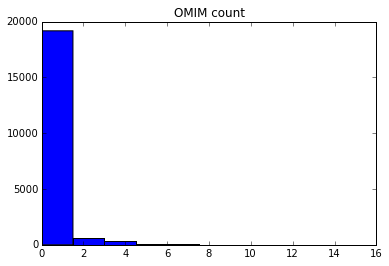

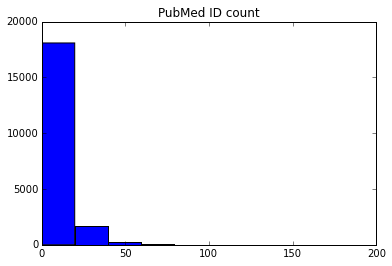

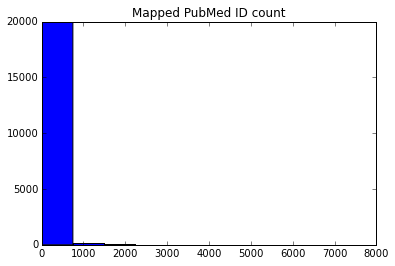

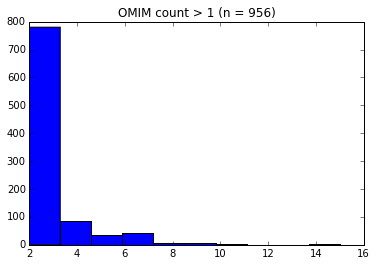

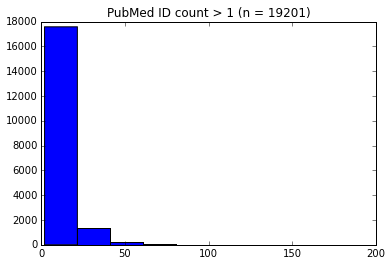

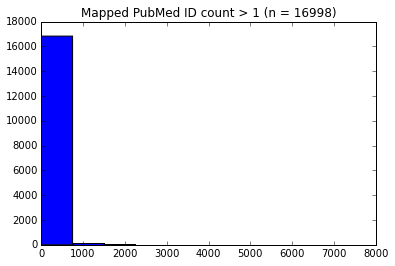

In [3]:
reviewed_df = load_plot_annotations(reviewed_annot_file)

## Analyze all human proteins
Protein list as of as of 12/9/16

Loaded 156576 UniProt annotations

Top 5 values in OMIM count: [15, 15, 12, 10, 10]
Top 5 values in PubMed ID count: [275, 250, 214, 213, 210]
Top 5 values in Mapped PubMed ID count: [7481, 6636, 6635, 6635, 6634]

99th percentile in OMIM count: 1.0
95th percentile in OMIM count: 0.0
90th percentile in OMIM count: 0.0
75th percentile in OMIM count: 0.0
50th percentile in OMIM count: 0.0

99th percentile in PubMed ID count: 23.0
95th percentile in PubMed ID count: 10.0
90th percentile in PubMed ID count: 6.0
75th percentile in PubMed ID count: 3.0
50th percentile in PubMed ID count: 2.0

99th percentile in Mapped PubMed ID count: 2259.0
95th percentile in Mapped PubMed ID count: 1232.0
90th percentile in Mapped PubMed ID count: 607.0
75th percentile in Mapped PubMed ID count: 36.0
50th percentile in Mapped PubMed ID count: 2.0



C:\Program Files\Anaconda\lib\site-packages\IPython\core\interactiveshell.py:3032: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


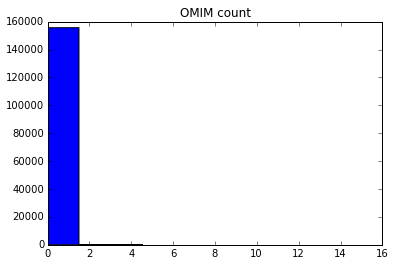

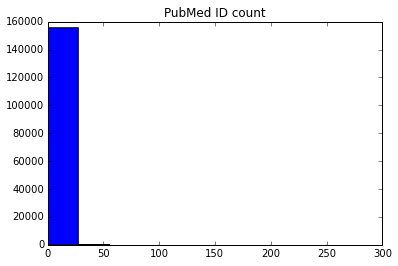

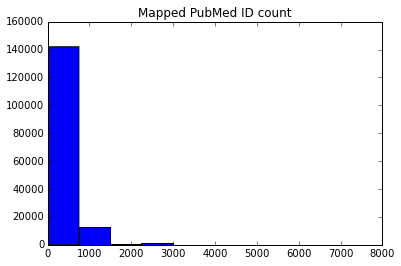

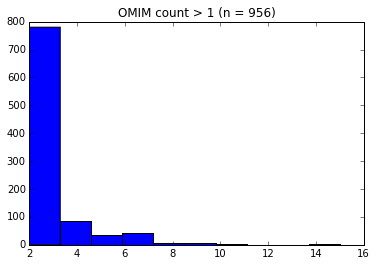

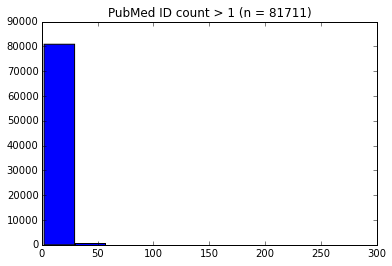

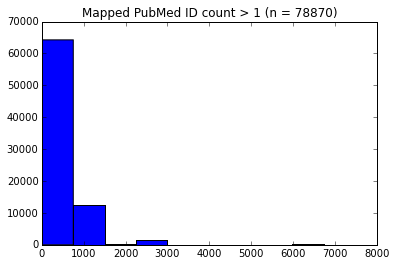

In [4]:
all_df = load_plot_annotations(all_annot_file)

## Load the TPS pathway members

In [5]:
tps_df = pd.read_excel(tps_network_file, sheetname='p-0.01 first-prev monotonicity', convert_float=False)
tps_proteins = set()
tps_proteins.update(tps_df['source'].values)
tps_proteins.update(tps_df['target'].values)
print 'Loaded {} TPS pathway edges'.format(len(tps_df))
print 'Loaded {} TPS pathway nodes'.format(len(tps_proteins))

Loaded 413 TPS pathway edges
Loaded 311 TPS pathway nodes


## Find the TPS pathway members that are well-studied or less-studied
**Very well-studied** means the protein is in at least the 99th percentile for OMIM disease associations and manual PubMed associations.

**Well-studied** means the protein is in at least the 95th percentile for OMIM disease associations and manual PubMed associations.

**Partially-studied** means the protein is in less than the 50th percentile for manual PubMed associations.

**Unstudied** means the protein has 0 OMIM disease associations and manual PubMed associations.  Do not rely on computationally mapped PubMed associations.

Note that not all of the 311 TPS proteins are in the list of reviewed proteins or all human proteins, which likely indicates changes to the UniProt ids.

In [6]:
tps_reviewed_df = reviewed_df[reviewed_df['Entry name'].isin(tps_proteins)]

very_reviewed_df = reviewed_df[(reviewed_df['OMIM count'] >= np.percentile(reviewed_df['OMIM count'].values, 99)) & 
                               (reviewed_df['PubMed ID count'] >= np.percentile(reviewed_df['PubMed ID count'].values, 99))]
tps_very_reviewed_df = very_reviewed_df[very_reviewed_df['Entry name'].isin(tps_proteins)]

well_reviewed_df = reviewed_df[(reviewed_df['OMIM count'] >= np.percentile(reviewed_df['OMIM count'].values, 95)) & 
                               (reviewed_df['PubMed ID count'] >= np.percentile(reviewed_df['PubMed ID count'].values, 95))]
tps_well_reviewed_df = well_reviewed_df[well_reviewed_df['Entry name'].isin(tps_proteins)]

part_reviewed_df = reviewed_df[reviewed_df['PubMed ID count'] < np.percentile(reviewed_df['PubMed ID count'].values, 50)]
tps_part_reviewed_df = part_reviewed_df[part_reviewed_df['Entry name'].isin(tps_proteins)]

un_reviewed_df = reviewed_df[(reviewed_df['OMIM count'] == 0) & 
                               (reviewed_df['PubMed ID count'] == 0)]
tps_un_reviewed_df = un_reviewed_df[un_reviewed_df['Entry name'].isin(tps_proteins)]


tps_all_df = all_df[all_df['Entry name'].isin(tps_proteins)]

very_all_df = all_df[(all_df['OMIM count'] >= np.percentile(all_df['OMIM count'].values, 99)) & 
                               (all_df['PubMed ID count'] >= np.percentile(all_df['PubMed ID count'].values, 99))]
tps_very_all_df = very_all_df[very_all_df['Entry name'].isin(tps_proteins)]

well_all_df = all_df[(all_df['OMIM count'] >= np.percentile(all_df['OMIM count'].values, 95)) & 
                               (all_df['PubMed ID count'] >= np.percentile(all_df['PubMed ID count'].values, 95))]
tps_well_all_df = well_all_df[well_all_df['Entry name'].isin(tps_proteins)]

part_all_df = all_df[all_df['PubMed ID count'] < np.percentile(all_df['PubMed ID count'].values, 50)]
tps_part_all_df = part_all_df[part_all_df['Entry name'].isin(tps_proteins)]

un_all_df = all_df[(all_df['OMIM count'] == 0) & 
                               (all_df['PubMed ID count'] == 0)]
tps_un_all_df = un_all_df[un_all_df['Entry name'].isin(tps_proteins)]


print '{} very well-studied reviewed proteins, {} are TPS pathway members'.format(len(very_reviewed_df),len(tps_very_reviewed_df))
print '{} well-studied reviewed proteins, {} are TPS pathway members'.format(len(well_reviewed_df),len(tps_well_reviewed_df))
print '{} partially-studied reviewed proteins, {} are TPS pathway members'.format(len(part_reviewed_df),len(tps_part_reviewed_df))
print '{} unstudied reviewed proteins, {} are TPS pathway members'.format(len(un_reviewed_df),len(tps_un_reviewed_df))
print '{} total reviewed proteins, {} are TPS pathway members\n'.format(len(reviewed_df),len(tps_reviewed_df))


print '{} very well-studied proteins, {} are TPS pathway members'.format(len(very_all_df),len(tps_very_all_df))
print '{} well-studied proteins, {} are TPS pathway members'.format(len(well_all_df),len(tps_well_all_df))
print '{} partially-studied proteins, {} are TPS pathway members'.format(len(part_all_df),len(tps_part_all_df))
print '{} unstudied proteins, {} are TPS pathway members'.format(len(un_all_df),len(tps_un_all_df))
print '{} total proteins, {} are TPS pathway members\n'.format(len(all_df),len(tps_all_df))

print 'Very well-studied reviewed proteins in TPS pathway:'
print '\n'.join(sorted(tps_very_reviewed_df['Entry name'].values))

print '\nPartially-studied reviewed proteins in TPS pathway:'
print '\n'.join(sorted(tps_part_reviewed_df['Entry name'].values))

73 very well-studied reviewed proteins, 5 are TPS pathway members
543 well-studied reviewed proteins, 38 are TPS pathway members
9737 partially-studied reviewed proteins, 5 are TPS pathway members
72 unstudied reviewed proteins, 0 are TPS pathway members
20129 total reviewed proteins, 305 are TPS pathway members

699 very well-studied proteins, 44 are TPS pathway members
8920 well-studied proteins, 289 are TPS pathway members
74865 partially-studied proteins, 0 are TPS pathway members
53912 unstudied proteins, 0 are TPS pathway members
156576 total proteins, 308 are TPS pathway members

Very well-studied reviewed proteins in TPS pathway:
AKT1_HUMAN
APC_HUMAN
LMNA_HUMAN
MECP2_HUMAN
PTN11_HUMAN

Partially-studied reviewed proteins in TPS pathway:
MKX_HUMAN
NHLC2_HUMAN
PTN18_HUMAN
REC8_HUMAN
SPY1_HUMAN


## Very well-studied reviewed proteins in TPS pathway

In [7]:
tps_very_reviewed_df.sort_values(by='PubMed ID count').head(100)

,Entry,Entry name,Status,Protein names,Gene names,Organism,Involvement in disease,PubMed ID,Mapped PubMed ID,OMIM count,PubMed ID count,Mapped PubMed ID count
8239,P25054,APC_HUMAN,reviewed,Adenomatous polyposis coli protein (Protein AP...,APC DP2.5,Homo sapiens (Human),DISEASE: Familial adenomatous polyposis (FAP) ...,1678319; 1651562; 10947987; 1310068; 8259519; ...,1678319; 1651562; 10947987; 1310068; 8259519; ...,5,56,639
16827,P51608,MECP2_HUMAN,reviewed,Methyl-CpG-binding protein 2 (MeCp-2 protein) ...,MECP2,Homo sapiens (Human),DISEASE: Angelman syndrome (AS) [MIM:105830]: ...,9710633; 8976388; 10369871; 10723722; 15034579...,9710633; 8976388; 10369871; 10723722; 15034579...,6,59,428
3464,Q06124,PTN11_HUMAN,reviewed,Tyrosine-protein phosphatase non-receptor type...,PTPN11 PTP2C SHPTP2,Homo sapiens (Human),DISEASE: LEOPARD syndrome 1 (LPRD1) [MIM:15110...,1281790; 1280823; 8216283; 7681589; 7681217; 1...,1281790; 1280823; 8216283; 7681589; 7681217; 1...,4,67,473
17,P31749,AKT1_HUMAN,reviewed,RAC-alpha serine/threonine-protein kinase (EC ...,AKT1 PKB RAC,Homo sapiens (Human),DISEASE: Breast cancer (BC) [MIM:114480]: A co...,1851997; 11508278; 14702039; 19054851; 1250812...,1851997; 11508278; 14702039; 19054851; 1250812...,4,83,2549
16447,P02545,LMNA_HUMAN,reviewed,Prelamin-A/C [Cleaved into: Lamin-A/C (70 kDa ...,LMNA LMN1,Homo sapiens (Human),"DISEASE: Emery-Dreifuss muscular dystrophy 2, ...",3453101; 3462705; 16061563; 14702039; 16710414...,3453101; 3462705; 16061563; 14702039; 16710414...,12,103,527


## Partially-studied reviewed proteins in TPS pathway

In [8]:
tps_part_reviewed_df.sort_values(by='PubMed ID count').head(100)

,Entry,Entry name,Status,Protein names,Gene names,Organism,Involvement in disease,PubMed ID,Mapped PubMed ID,OMIM count,PubMed ID count,Mapped PubMed ID count
17234,Q8IYA7,MKX_HUMAN,reviewed,Homeobox protein Mohawk,MKX C10orf48 IRXL1,Homo sapiens (Human),NaN,14702039; 15164054; 15489334,14702039; 15164054; 15489334; 16077953; 206348...,0,3,9
18412,O43609,SPY1_HUMAN,reviewed,Protein sprouty homolog 1 (Spry-1),SPRY1,Homo sapiens (Human),NaN,14533010; 15489334; 9458049; 22223895,14533010; 15489334; 9458049; 22223895; 1198389...,0,4,35
531,Q8NBF2,NHLC2_HUMAN,reviewed,NHL repeat-containing protein 2,NHLRC2,Homo sapiens (Human),NaN,14702039; 15164054; 15489334; 21269460; 24275569,14702039; 15164054; 15489334; 21269460; 242755...,0,5,7
3735,O95072,REC8_HUMAN,reviewed,Meiotic recombination protein REC8 homolog (Co...,REC8 REC8L1,Homo sapiens (Human),NaN,10207075; 14702039; 17974005; 12508121; 15489334,10207075; 14702039; 17974005; 12508121; 154893...,0,5,10
3442,Q99952,PTN18_HUMAN,reviewed,Tyrosine-protein phosphatase non-receptor type...,PTPN18 BDP1,Homo sapiens (Human),NaN,8950995; 14702039; 15815621; 19690332; 2318616...,8950995; 14702039; 15815621; 19690332; 2318616...,0,6,15
